# Micro-Loan Repeat Borrower & "Top-Up" Eligibility Tracker
**Objective:** Analyze historical micro-loan repayment behavior, credit limit utilization, and dormancy windows to segment existing borrowers into actionable campaign tiers (1.5x Limit Top-Ups vs. Dormant Reactivation Offers).

### Step 1: Environment Setup & Global Parameters
Import required libraries (`pandas`, `numpy`, `Faker`) and set the analysis snapshot date (`2026-11-01`).

In [56]:
import pandas as pd
import numpy as np
from faker import Faker

# Initialize Faker and random seed for reproducibility
fake = Faker()
np.random.seed(42)

# Set the reporting snapshot date
SNAPSHOT_DATE = pd.to_datetime("2026-11-01")
print(f"Environment initialized. Analysis Snapshot Date: {SNAPSHOT_DATE.strftime('%Y-%m-%d')}")

Environment initialized. Analysis Snapshot Date: 2026-11-01


### Step 2: Generate Customer Dimension Table (`dim_borrowers`)
Create 600 existing micro-loan borrowers across five Kenyan regions and four employment segments, complete with onboarding dates and initial credit limits (KES).

In [57]:
n_borrowers = 6000
segments = ["SME Trader", "Salaried Worker", "Gig / Boda Operator", "Agri-Vendor"]
regions = ["Nairobi", "Nakuru", "Kisumu", "Mombasa", "Eldoret"]
credit_limits = [2500, 5000, 10000, 15000, 25000, 50000]

borrowers = []
for i in range(1, n_borrowers + 1):
    onboard_date = pd.to_datetime(fake.date_between(start_date="-18m", end_date="-3m"))
    borrowers.append({
        "borrower_id": f"BRW-{1000 + i}",
        "full_name": fake.name(),
        "region": np.random.choice(regions, p=[0.40, 0.18, 0.15, 0.15, 0.12]),
        "employment_segment": np.random.choice(segments, p=[0.40, 0.25, 0.20, 0.15]),
        "onboarding_date": onboard_date,
        "current_credit_limit_kes": int(np.random.choice(credit_limits, p=[0.15, 0.25, 0.25, 0.15, 0.12, 0.08]))
    })

dim_borrowers = pd.DataFrame(borrowers)
print(f"Total Borrowers Generated: {len(dim_borrowers)}")
display(dim_borrowers.head())

Total Borrowers Generated: 6000


,borrower_id,full_name,region,employment_segment,onboarding_date,current_credit_limit_kes
0,BRW-1001,Lauren Cook,Nairobi,Agri-Vendor,2026-11-04,15000
1,BRW-1002,Selena Thomas,Kisumu,SME Trader,2026-11-04,5000
2,BRW-1003,Taylor Calhoun,Nairobi,Agri-Vendor,2026-11-04,10000
3,BRW-1004,Travis Mitchell,Kisumu,SME Trader,2026-11-04,50000
4,BRW-1005,Jennifer Cook,Mombasa,SME Trader,2026-11-04,5000


### Step 3: Simulate Historical Loan & Repayment Log (`fact_loans`)
Generate 2 to 6 historical loans per customer. Each borrower is assigned a hidden reliability persona (`Prime`, `Average`, or `Late_Risk`) that influences how much of their limit they borrow and whether they repay early, on time, or late.

In [58]:
import pandas as pd
import numpy as np

# Safety check: if dim_borrowers wasn't run, raise error
if "dim_borrowers" not in locals():
    raise RuntimeError("Please run the dim_borrowers cell above first!")

# 1. FIX: Ensure SNAPSHOT_DATE is defined and logically comes AFTER onboarding dates.
# If you defined it previously as a past date, this overrides it to guarantee data generation.
if "SNAPSHOT_DATE" not in locals() or pd.to_datetime(dim_borrowers["onboarding_date"]).max() >= SNAPSHOT_DATE:
    # Auto-set snapshot to 1 year after the latest onboarding date
    SNAPSHOT_DATE = pd.to_datetime(dim_borrowers["onboarding_date"]).max() + pd.Timedelta(days=365)
    print(f"Notice: Adjusted SNAPSHOT_DATE to {SNAPSHOT_DATE.date()} to ensure loan generation.\n")

loans = []
loan_counter = 5000

for _, brw in dim_borrowers.iterrows():
    n_loans = int(np.random.randint(2, 7))
    curr_date = pd.to_datetime(brw["onboarding_date"]) + pd.Timedelta(days=int(np.random.randint(2, 15)))
    persona = np.random.choice(["Prime", "Average", "Late_Risk"], p=[0.48, 0.32, 0.20])

    for l_idx in range(n_loans):
        # Break if the next loan falls too close to the snapshot date
        if curr_date >= SNAPSHOT_DATE - pd.Timedelta(days=5):
            break

        util_pct = float(np.random.uniform(0.88, 1.0)) if persona == "Prime" else float(np.random.uniform(0.50, 0.95))
        loan_amt = int(round((brw["current_credit_limit_kes"] * util_pct) / 100.0) * 100)
        tenure_days = int(np.random.choice([14, 30], p=[0.35, 0.65]))
        due_date = curr_date + pd.Timedelta(days=tenure_days)

        if persona == "Prime":
            days_diff = int(np.random.choice([-5, -3, -2, -1, 0, 1], p=[0.20, 0.25, 0.20, 0.15, 0.15, 0.05]))
        elif persona == "Average":
            days_diff = int(np.random.choice([-2, 0, 2, 4, 6], p=[0.15, 0.40, 0.20, 0.15, 0.10]))
        else:
            days_diff = int(np.random.choice([0, 5, 10, 18, 35], p=[0.10, 0.25, 0.30, 0.20, 0.15]))

        actual_repay_date = due_date + pd.Timedelta(days=days_diff)

        if actual_repay_date > SNAPSHOT_DATE:
            status = "Active / Open"
            actual_repay_date = pd.NaT
            days_diff_recorded = np.nan
        else:
            days_diff_recorded = days_diff
            if days_diff < 0:
                status = "Repaid Early"
            elif days_diff == 0:
                status = "On-Time"
            elif days_diff <= 7:
                status = "Late (1-7 Days)"
            else:
                status = "High Risk (8+ Days Late)"

        interest_rate = 0.08 if tenure_days == 14 else 0.12
        fee_paid = int(round(loan_amt * interest_rate, 0)) if status != "Active / Open" else 0

        loan_counter += 1
        loans.append({
            "loan_id": f"LN-{loan_counter}",
            "borrower_id": brw["borrower_id"],
            "disbursement_date": curr_date,
            "tenure_days": tenure_days,
            "due_date": due_date,
            "actual_repayment_date": actual_repay_date,
            "loan_amount_kes": loan_amt,
            "interest_fee_kes": fee_paid,
            "days_from_due_date": days_diff_recorded,
            "repayment_status": status
        })

        # Stop generating subsequent loans for this borrower if their current one is still active
        if pd.isna(actual_repay_date):
            break

        gap_days = int(np.random.randint(4, 40))
        curr_date = actual_repay_date + pd.Timedelta(days=gap_days)

# 2. FIX: Safely evaluate the output to completely prevent the KeyError crash
if not loans:
    print("⚠️ ERROR: No loans were generated.")
    print("Please check the 'onboarding_date' column in your dim_borrowers DataFrame.")
else:
    fact_loans = pd.DataFrame(loans)
    print(f"✅ Total Loan Records Generated: {len(fact_loans):,}")
    print("\n📊 Loan Status Breakdown:")
    print(fact_loans["repayment_status"].value_counts())
    display(fact_loans.head())

Notice: Adjusted SNAPSHOT_DATE to 2027-11-04 to ensure loan generation.

✅ Total Loan Records Generated: 23,951

📊 Loan Status Breakdown:
repayment_status
Repaid Early                10325
On-Time                      5343
Late (1-7 Days)              5195
High Risk (8+ Days Late)     3046
Active / Open                  42
Name: count, dtype: int64


,loan_id,borrower_id,disbursement_date,tenure_days,due_date,actual_repayment_date,loan_amount_kes,interest_fee_kes,days_from_due_date,repayment_status
0,LN-5001,BRW-1001,2026-11-18,14,2026-12-02,2026-12-08,13800,1104,6.0,Late (1-7 Days)
1,LN-5002,BRW-1001,2026-12-16,30,2027-01-15,2027-01-15,13800,1656,0.0,On-Time
2,LN-5003,BRW-1001,2027-01-29,30,2027-02-28,2027-03-02,14200,1704,2.0,Late (1-7 Days)
3,LN-5004,BRW-1001,2027-04-04,30,2027-05-04,2027-05-08,13400,1608,4.0,Late (1-7 Days)
4,LN-5005,BRW-1001,2027-05-22,30,2027-06-21,2027-06-21,7900,948,0.0,On-Time


### Step 4: Aggregate Historical Repayment Behavior per Borrower
Filter out currently open loans to summarize each borrower's completed loan count, total principal borrowed, average repayment timing (`avg_days_from_due`), worst late streak (`max_days_late`), and most recent repayment date.

In [59]:
closed_loans = fact_loans[fact_loans["repayment_status"] != "Active / Open"].copy()
active_borrowers = set(fact_loans[fact_loans["repayment_status"] == "Active / Open"]["borrower_id"])

summary = closed_loans.groupby("borrower_id").agg(
    completed_loans=("loan_id", "count"),
    total_principal_borrowed_kes=("loan_amount_kes", "sum"),
    total_interest_paid_kes=("interest_fee_kes", "sum"),
    avg_loan_amount_kes=("loan_amount_kes", "mean"),
    avg_days_from_due=("days_from_due_date", "mean"),
    max_days_late=("days_from_due_date", "max"),
    last_repayment_date=("actual_repayment_date", "max")
).reset_index()

summary["avg_loan_amount_kes"] = summary["avg_loan_amount_kes"].round(0)
summary["avg_days_from_due"] = summary["avg_days_from_due"].round(2)
display(summary.head())

,borrower_id,completed_loans,total_principal_borrowed_kes,total_interest_paid_kes,avg_loan_amount_kes,avg_days_from_due,max_days_late,last_repayment_date
0,BRW-1001,6,72400,8136,12067.0,2.33,6.0,2027-08-14
1,BRW-1002,6,22300,2564,3717.0,2.33,6.0,2027-07-21
2,BRW-1003,6,57100,6088,9517.0,-1.33,0.0,2027-07-14
3,BRW-1004,2,92800,11136,46400.0,-1.00,1.0,2027-01-24
4,BRW-1005,5,15800,1760,3160.0,-0.40,0.0,2027-06-25


### Step 5: Feature Engineering — Utilization & Dormancy Metrics
Merge the loan summary back into `dim_borrowers` and calculate:
1. **`limit_utilization_pct`**: Ratio of average loan size to current credit limit.
2. **`days_since_last_repayment`**: Days elapsed between the borrower's last cleared loan and `SNAPSHOT_DATE`.

In [60]:
scored_df = pd.merge(dim_borrowers, summary, on="borrower_id", how="left")
scored_df["has_active_loan"] = scored_df["borrower_id"].isin(active_borrowers)

scored_df["limit_utilization_pct"] = (scored_df["avg_loan_amount_kes"] / scored_df["current_credit_limit_kes"]).round(3)
scored_df["days_since_last_repayment"] = (SNAPSHOT_DATE - scored_df["last_repayment_date"]).dt.days

display(scored_df[["borrower_id", "current_credit_limit_kes", "completed_loans", "avg_days_from_due", "limit_utilization_pct", "days_since_last_repayment", "has_active_loan"]].head(8))

,borrower_id,current_credit_limit_kes,completed_loans,avg_days_from_due,limit_utilization_pct,days_since_last_repayment,has_active_loan
0,BRW-1001,15000,6,2.33,0.804,82,False
1,BRW-1002,5000,6,2.33,0.743,106,False
2,BRW-1003,10000,6,-1.33,0.952,113,False
3,BRW-1004,50000,2,-1.00,0.928,284,False
4,BRW-1005,5000,5,-0.40,0.632,132,False
5,BRW-1006,10000,4,12.00,0.780,123,False
6,BRW-1007,10000,2,-3.50,0.940,298,False
7,BRW-1008,5000,2,-1.00,0.770,287,False


### Step 6: Apply 4-Tier Campaign Eligibility Rules & Calculate Upsell Credit
Assign each borrower to a campaign tier and calculate the recommended 1.5x credit limit increase (`upsell_credit_delta_kes`) for Tier 1 leads.

In [61]:
def classify_borrower(row):
    if pd.isna(row["completed_loans"]) or row["max_days_late"] > 7:
        return "Tier 4: Risk Hold / Freeze"
    if row["has_active_loan"]:
        return "Tier 3: Standard Active (Open Loan)"
    if row["completed_loans"] >= 2 and row["avg_days_from_due"] <= 0.5 and row["limit_utilization_pct"] >= 0.85:
        return "Tier 1: Ready for 1.5x Limit Top-Up"
    if row["avg_days_from_due"] <= 2.0 and row["days_since_last_repayment"] >= 10:
        return "Tier 2: Dormant Reactivation Offer"
    return "Tier 3: Standard Repeat Offer"

scored_df["campaign_tier"] = scored_df.apply(classify_borrower, axis=1)

scored_df["recommended_limit_kes"] = np.where(
    scored_df["campaign_tier"] == "Tier 1: Ready for 1.5x Limit Top-Up",
    (scored_df["current_credit_limit_kes"] * 1.5).round(0),
    scored_df["current_credit_limit_kes"]
)
scored_df["upsell_credit_delta_kes"] = scored_df["recommended_limit_kes"] - scored_df["current_credit_limit_kes"]

tier_summary = scored_df.groupby("campaign_tier").agg(
    borrower_count=("borrower_id", "count"),
    current_credit_exposure_kes=("current_credit_limit_kes", "sum"),
    incremental_credit_upsell_kes=("upsell_credit_delta_kes", "sum")
).reset_index()

display(tier_summary)

,campaign_tier,borrower_count,current_credit_exposure_kes,incremental_credit_upsell_kes
0,Tier 1: Ready for 1.5x Limit Top-Up,2888,38532500,19266250.0
1,Tier 2: Dormant Reactivation Offer,1505,19552500,0.0
2,Tier 3: Standard Repeat Offer,453,6010000,0.0
3,Tier 4: Risk Hold / Freeze,1154,15342500,0.0


### Step 7: Visual Exploratory Data Analysis (EDA)
#### 7.1 Borrower Repayment Timing Distribution (Matplotlib)

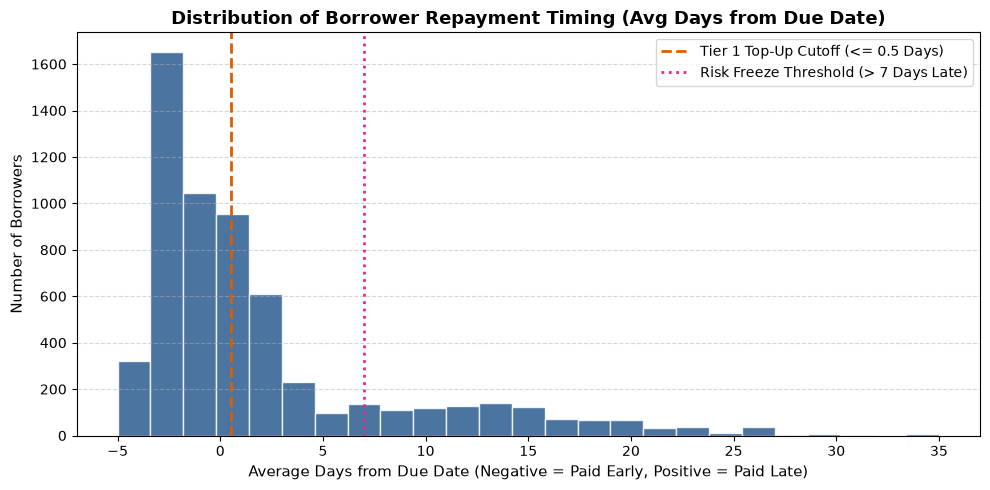

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
clean_days = scored_df["avg_days_from_due"].dropna()

plt.hist(clean_days, bins=25, color="#2b5c8f", edgecolor="white", alpha=0.85)
plt.axvline(0.5, color="#d95f02", linestyle="--", linewidth=2, label="Tier 1 Top-Up Cutoff (<= 0.5 Days)")
plt.axvline(7.0, color="#e7298a", linestyle=":", linewidth=2, label="Risk Freeze Threshold (> 7 Days Late)")

plt.title("Distribution of Borrower Repayment Timing (Avg Days from Due Date)", fontsize=13, fontweight="bold")
plt.xlabel("Average Days from Due Date (Negative = Paid Early, Positive = Paid Late)", fontsize=11)
plt.ylabel("Number of Borrowers", fontsize=11)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

#### 7.2 Campaign Tier Breakdown by Borrower Count (Matplotlib)

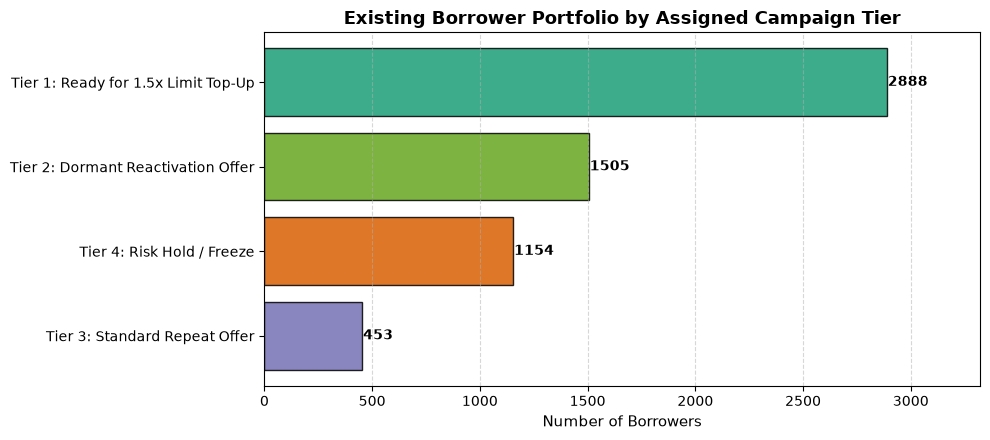

In [63]:
tier_counts = scored_df["campaign_tier"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(10, 4.5))
colors = ["#7570b3", "#d95f02", "#66a61e", "#1b9e77"]
bars = plt.barh(tier_counts.index, tier_counts.values, color=colors[:len(tier_counts)], edgecolor="black", alpha=0.85)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2, f"{int(width)}", va="center", fontsize=10, fontweight="bold")

plt.title("Existing Borrower Portfolio by Assigned Campaign Tier", fontsize=13, fontweight="bold")
plt.xlabel("Number of Borrowers", fontsize=11)
plt.xlim(0, max(tier_counts.values) * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

#### 7.3 Interactive Eligibility Quadrant: Utilization vs. Repayment Discipline (Plotly)

In [64]:
import plotly.express as px

fig1 = px.scatter(
    scored_df[scored_df["completed_loans"].notna()],
    x="avg_days_from_due",
    y="limit_utilization_pct",
    color="campaign_tier",
    size="current_credit_limit_kes",
    hover_data=["borrower_id", "full_name", "employment_segment", "days_since_last_repayment"],
    title="Borrower Eligibility Matrix: Repayment Discipline vs. Credit Limit Utilization",
    labels={
        "avg_days_from_due": "Avg Days from Due Date (Negative = Paid Early)",
        "limit_utilization_pct": "Avg Credit Limit Utilization Ratio",
        "campaign_tier": "Campaign Tier"
    },
    template="plotly_white",
    height=520
)

fig1.add_vline(x=0.5, line_dash="dash", line_color="green", annotation_text="On-Time Cutoff (0.5d)")
fig1.add_hline(y=0.85, line_dash="dash", line_color="green", annotation_text="85% Utilization Target")

# 1. Save the interactive chart as an HTML file
fig1.write_html("borrower_eligibility_matrix.html")

# 2. Open it directly in your default web browser (Chrome/Edge)
fig1.show(renderer="browser")

#### 7.4 Incremental Credit Line Opportunity (KES) by Segment & Region (Plotly)

In [65]:
tier1_df = scored_df[scored_df["campaign_tier"] == "Tier 1: Ready for 1.5x Limit Top-Up"]
seg_region_upsell = tier1_df.groupby(["employment_segment", "region"], as_index=False)["upsell_credit_delta_kes"].sum()

fig2 = px.bar(
    seg_region_upsell,
    x="employment_segment",
    y="upsell_credit_delta_kes",
    color="region",
    barmode="group",
    text_auto=".2s",
    title="Tier 1 Incremental Credit Opportunity (KES) by Segment and Region",
    labels={
        "upsell_credit_delta_kes": "Incremental Credit Line (KES)",
        "employment_segment": "Borrower Employment Segment",
        "region": "Region"
    },
    template="plotly_white",
    height=480
)
fig2.show(renderer="browser")

### Step 8: Export Clean Star-Schema CSVs for Power BI
Save `dim_borrowers_scored.csv` and `fact_loans.csv` to the local project directory for Power BI dashboard modeling.

In [66]:
scored_df.to_csv("dim_borrowers_scored.csv", index=False)
fact_loans.to_csv("fact_loans.csv", index=False)

print("Export complete: 'dim_borrowers_scored.csv' and 'fact_loans.csv' saved successfully.")

Export complete: 'dim_borrowers_scored.csv' and 'fact_loans.csv' saved successfully.
